# 01 - Data cleaning, SQL and EDA

**Business question:** a grocery retailer wants to send retention coupons to households that are about to stop shopping.
Before building a model we need to understand the data and decide what "stopped shopping" (churn) means.

**Data:** dunnhumby *The Complete Journey*: about 2,500 households, 102 weeks of transactions, plus a product table and demographics.
All tables below are built by the SQL files in `sql/`, run with DuckDB directly on the raw CSVs.

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the repo root whether the notebook is opened from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Raw data and data quality

In [2]:
from src.data import load_transactions, quality_report

tx = load_transactions()
print(f"{len(tx):,} rows (one row = one product line in a basket)")
print(f"{tx['household_key'].nunique():,} households, {tx['basket_id'].nunique():,} baskets, weeks {tx['week_no'].min()}..{tx['week_no'].max()}")
quality_report(tx)

2,595,732 rows (one row = one product line in a basket)
2,500 households, 276,484 baskets, weeks 1..102


,dtype,n_missing,n_unique,min,max
household_key,int64,0,2500,1.000e+00,2.500e+03
basket_id,int64,0,276484,2.698e+10,4.231e+10
day,int64,0,711,1.000e+00,7.110e+02
product_id,int64,0,92339,2.567e+04,1.832e+07
quantity,int64,0,11746,0.000e+00,8.964e+04
sales_value,float64,0,5502,0.000e+00,8.400e+02
store_id,int64,0,582,1.000e+00,3.428e+04
retail_disc,float64,0,2414,-1.800e+02,3.990e+00
trans_time,int64,0,1440,0.000e+00,2.359e+03
week_no,int64,0,102,1.000e+00,1.020e+02


In [3]:
checks = {
    "missing values": int(tx.isna().sum().sum()),
    "fully duplicated rows": int(tx.duplicated().sum()),
    "rows with sales_value <= 0 (returns / free items)": int((tx["sales_value"] <= 0).sum()),
    "rows with quantity = 0": int((tx["quantity"] == 0).sum()),
    "rows with a coupon discount": int((tx["coupon_disc"] < 0).sum()),
}
pd.Series(checks, name="count").to_frame().assign(share=lambda d: d["count"] / len(tx))

,count,share
missing values,0,0.000
fully duplicated rows,0,0.000
rows with sales_value <= 0 (returns / free items),18850,0.007
rows with quantity = 0,14466,0.006
rows with a coupon discount,36422,0.014


**Cleaning decisions**
* There are no missing values in the transactions and no duplicated rows.
* Rows with `sales_value <= 0` are returns or free items. We **keep** them, because they are part of the real net spend,
  but a week only counts as a **purchase week** when the household's net sales in that week are > 0.
* Discounts (`retail_disc`, `coupon_disc`, `coupon_match_disc`) are stored as **negative** numbers; we flip the sign in SQL.
* The data is at product-line level. We aggregate it to **household x week** in SQL (next section).

In [4]:
del tx   # 2.6M rows: free the memory, from here on we work with the SQL results

## 2. SQL: household x week activity table (GROUP BY + JOIN with products)

In [5]:
from src.config import SQL_DIR
from src.data import connect, run_sql

con = connect()
print((SQL_DIR / "01_weekly_activity.sql").read_text())
weekly = run_sql(SQL_DIR / "01_weekly_activity.sql", con)
weekly.describe().T

-- Household x week activity: one row per household and week with at least one transaction.
-- transaction_data has one row per product line, so we aggregate to avoid counting a basket many times.
-- Returns are kept (net_sales can be <= 0); a week only counts as "active" later if net_sales > 0.
-- Discounts are stored as negative numbers in the raw data, so we flip the sign.

SELECT
    t.household_key,
    t.week_no,
    COUNT(DISTINCT t.basket_id)                                        AS n_baskets,
    COUNT(*)                                                           AS n_items,
    COUNT(DISTINCT p.department)                                       AS n_departments,
    SUM(t.sales_value)                                                 AS net_sales,
    -SUM(t.retail_disc + t.coupon_disc + t.coupon_match_disc)          AS discount_amount,
    SUM(CASE WHEN t.coupon_disc < 0 THEN 1 ELSE 0 END)                 AS n_coupon_items
FROM transaction_data AS t
LEFT JOIN product AS p ON p.

,count,mean,std,min,25%,50%,75%,max
household_key,123976.0,1248.429,724.129,1.000e+00,624.00,1246.00,1883.00,2500.00
week_no,123976.0,55.711,27.253,1.000e+00,32.00,56.00,79.00,102.00
n_baskets,123976.0,2.230,1.926,1.000e+00,1.00,2.00,3.00,35.00
n_items,123976.0,20.937,20.499,1.000e+00,6.00,15.00,30.00,259.00
n_departments,123976.0,3.927,2.148,1.000e+00,2.00,4.00,5.00,14.00
net_sales,123976.0,64.992,66.119,0.000e+00,18.73,43.51,89.96,1283.33
discount_amount,123976.0,11.684,14.371,-4.441e-16,2.02,6.82,16.28,513.14
n_coupon_items,123976.0,0.294,1.285,0.000e+00,0.00,0.00,0.00,49.00


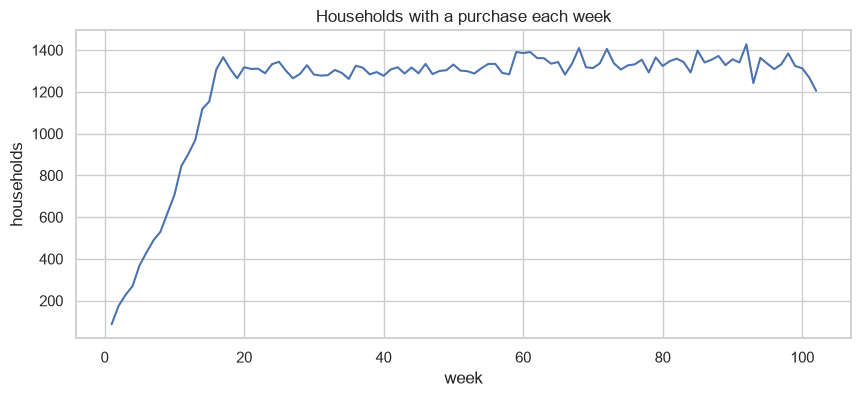

In [6]:
active = weekly[weekly["net_sales"] > 0]
per_week = active.groupby("week_no")["household_key"].nunique()

fig, ax = plt.subplots(figsize=(10, 4))
per_week.plot(ax=ax)
ax.set(title="Households with a purchase each week", xlabel="week", ylabel="households")
fig.savefig(FIGURES_DIR / "weekly_active_households.png", dpi=120, bbox_inches="tight")
plt.show()

The number of active households grows during the first ~17 weeks (households are still "entering" the panel) and is then stable.
That is why the first snapshot used for modelling is week 30 (`FIRST_CUTOFF` in `src/config.py`).

## 3. Choosing the churn definition: how long is a normal gap between purchases? (SQL window function `LAG`)

If we call a household "churned" after a short silence, we will mostly flag normal shoppers who skip a week or two.
So we look at the gaps between consecutive purchase weeks of the same household.

In [7]:
print((SQL_DIR / "05_purchase_gaps.sql").read_text())
gaps = run_sql(SQL_DIR / "05_purchase_gaps.sql", con)
silent = gaps.loc[gaps["silent_weeks"] > 0, "silent_weeks"]       # 0 = bought again the next week
print(silent.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

-- Gaps between consecutive purchase weeks of each household, with the window function LAG.
-- silent_weeks = 0 means the household bought again the very next week.
-- Used in notebook 01 to choose the churn definition.

WITH purchase_weeks AS (
    SELECT household_key, week_no
    FROM transaction_data
    GROUP BY household_key, week_no
    HAVING SUM(sales_value) > 0
),
with_previous AS (
    SELECT
        household_key,
        week_no,
        LAG(week_no) OVER (PARTITION BY household_key ORDER BY week_no) AS previous_week
    FROM purchase_weeks
)
SELECT
    household_key,
    previous_week,
    week_no,
    week_no - previous_week - 1 AS silent_weeks
FROM with_previous
WHERE previous_week IS NOT NULL      -- the first purchase of a household has no previous week
ORDER BY household_key, week_no



count    34503.0
mean         2.9
std          4.8
min          1.0
50%          1.0
90%          6.0
95%          9.0
99%         24.0
max         94.0
Name: silent_weeks, dtype: float64


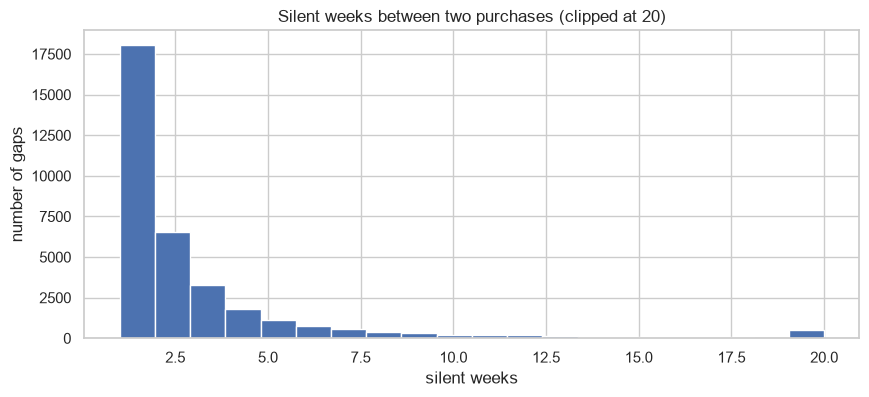

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
silent.clip(upper=20).plot.hist(bins=20, ax=ax)
ax.set(title="Silent weeks between two purchases (clipped at 20)", xlabel="silent weeks", ylabel="number of gaps")
fig.savefig(FIGURES_DIR / "purchase_gaps.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
print(f"Bought again the very next week: {(gaps['silent_weeks'] == 0).mean():.1%} of all gaps")
print(f"8+ silent weeks: {(silent >= 8).mean():.1%} of the gaps with a silence, "
      f"{(gaps['silent_weeks'] >= 8).mean():.1%} of all gaps")
print(f"12+ silent weeks: {(silent >= 12).mean():.1%} of the gaps with a silence")

Bought again the very next week: 71.6% of all gaps
8+ silent weeks: 6.8% of the gaps with a silence, 1.9% of all gaps
12+ silent weeks: 3.5% of the gaps with a silence


**Decision (see `src/config.py`):**
* **At risk** at week *c* = bought at least once in the last **12 weeks** (about 96% of silences are shorter than that).
* **Churn = 1** = **no purchase in the next 8 weeks**. Only about 7% of silences (2% of all gaps) are that long, so it is unusual for a regular shopper.

This measures *inactivity* (a "lapse"), not proof that the customer is gone forever.

## 4. SQL: demographics cleaning (LEFT JOIN + CASE) and missing values

In [10]:
print((SQL_DIR / "06_household_demographics.sql").read_text())
demographics = run_sql(SQL_DIR / "06_household_demographics.sql", con)
demographics.isna().mean().rename("share_missing").to_frame()

-- One row per household (all 2,500), with cleaned demographics.
-- Only ~1/3 of households have demographics, so the LEFT JOIN leaves NULLs: they are handled in the model pipeline.
-- Cleaning done here:
--   * text ranges -> numbers (income "50-74K" -> 62, household size "5+" -> 5) so the model can use their order
--   * "Unknown" / "None/Unknown" -> NULL, so a missing value looks the same everywhere

WITH households AS (
    SELECT DISTINCT household_key FROM transaction_data
)
SELECT
    h.household_key,
    CASE WHEN d.household_key IS NULL THEN 0 ELSE 1 END AS has_demographics,
    d.age_desc AS age_group,
    CASE d.income_desc
        WHEN 'Under 15K' THEN 10   WHEN '15-24K'   THEN 20  WHEN '25-34K'   THEN 30
        WHEN '35-49K'    THEN 42   WHEN '50-74K'   THEN 62  WHEN '75-99K'   THEN 87
        WHEN '100-124K'  THEN 112  WHEN '125-149K' THEN 137 WHEN '150-174K' THEN 162
        WHEN '175-199K'  THEN 187  WHEN '200-249K' THEN 225 WHEN '250K+'    THEN 275
    END AS income_k

,share_missing
household_key,0.000
has_demographics,0.000
age_group,0.680
income_k,0.680
household_size,0.680
homeowner,0.773


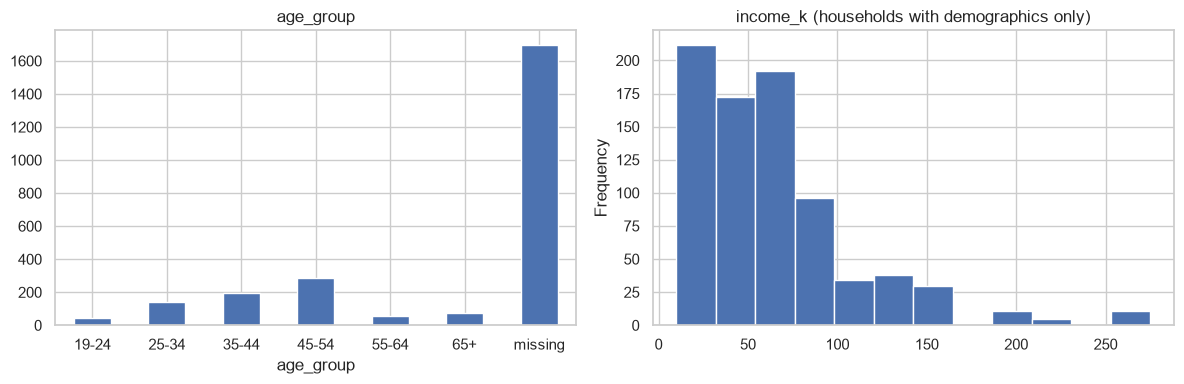

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
demographics["age_group"].fillna("missing").value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title="age_group")
demographics["income_k"].plot.hist(bins=12, ax=axes[1], title="income_k (households with demographics only)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "demographics.png", dpi=120, bbox_inches="tight")
plt.show()

Only about **32%** of households have demographics, so we cannot drop the rest. In the model (notebook 02):
* numeric columns (`income_k`, `household_size`) are filled with the **median** and the flag `has_demographics` tells the model which rows were filled;
* categorical columns (`age_group`, `homeowner`) get their own **"unknown"** category before one-hot encoding.

## 5. SQL: RFM segmentation (CTE + window function `NTILE`)

In [12]:
from src.business import segment_summary

rfm = run_sql(SQL_DIR / "02_rfm.sql", con)
segments = segment_summary(rfm)      # share of households vs share of sales per segment
segments

,segment,households,sales,median_active_weeks,median_recency_weeks,share_of_households,share_of_sales,sales_per_household
0,champions,609,3.760e+06,77.0,0.0,0.244,0.467,6173.353
1,middle,882,2.794e+06,51.0,1.0,0.353,0.347,3168.112
2,at_risk_loyal,155,6.789e+05,67.0,2.0,0.062,0.084,4380.223
3,lost,653,5.816e+05,22.0,5.0,0.261,0.072,890.702
4,new_or_light,201,2.431e+05,28.0,0.0,0.080,0.030,1209.223


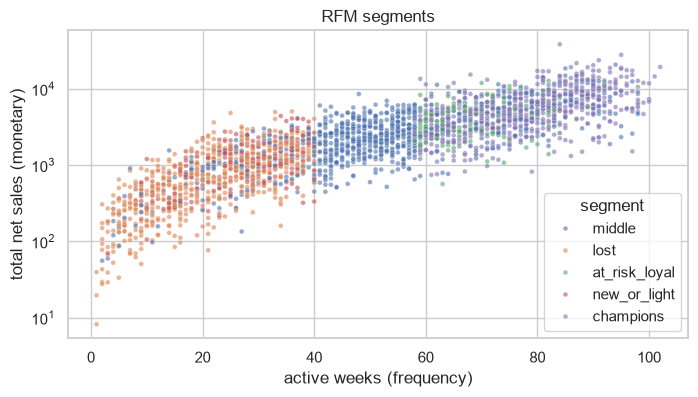

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=rfm, x="frequency_weeks", y="monetary", hue="segment", s=12, alpha=0.6, ax=ax)
ax.set(title="RFM segments", xlabel="active weeks (frequency)", ylabel="total net sales (monetary)", yscale="log")
fig.savefig(FIGURES_DIR / "rfm_segments.png", dpi=120, bbox_inches="tight")
plt.show()

**Who brings the money?** Champions are about **24%** of households but **47%** of sales, while lost households are **26%** of households and only **7%** of sales.
So losing one champion costs far more than losing one light shopper: this idea comes back in notebook 03 (rank by *expected sales lost*, not only by churn risk).

RFM uses the whole period (including the future), so it is only descriptive. The model in notebook 02 recomputes everything as of each cutoff week.

## 6. SQL: period-over-period retention (self LEFT JOIN)

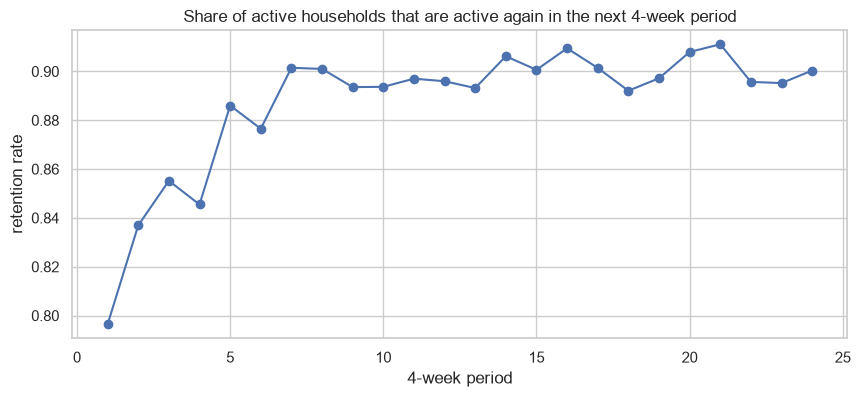

Median retention from one 4-week period to the next: 89.6%


In [14]:
retention = run_sql(SQL_DIR / "03_period_retention.sql", con)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(retention["period"], retention["retention_rate"], marker="o")
ax.set(title="Share of active households that are active again in the next 4-week period",
       xlabel="4-week period", ylabel="retention rate")
fig.savefig(FIGURES_DIR / "period_retention.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Median retention from one 4-week period to the next: {retention['retention_rate'].median():.1%}")

Retention is lower in the first periods (households are still entering the panel, as in the weekly chart) and then stable at about 90%.

## 7. SQL: sales by department (JOIN with the product table + window share)

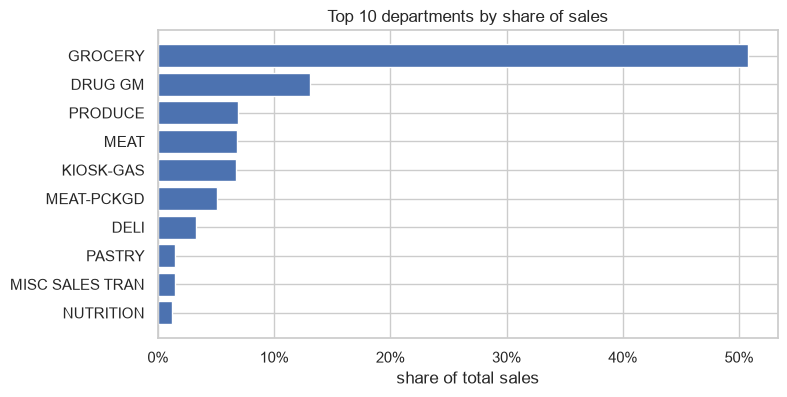

In [15]:
departments = run_sql(SQL_DIR / "04_department_sales.sql", con)

fig, ax = plt.subplots(figsize=(8, 4))
top = departments.head(10).iloc[::-1]
ax.barh(top["department"], top["share_of_sales"])
ax.set(title="Top 10 departments by share of sales", xlabel="share of total sales")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.savefig(FIGURES_DIR / "department_sales.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. SQL: weekly KPIs (CTE + conditional `COUNT`)

One row per week with the store-level KPIs: active households, baskets, net sales, average basket value and the share of the price that was discounted.

In [16]:
print((SQL_DIR / "07_weekly_kpis.sql").read_text())
kpis = run_sql(SQL_DIR / "07_weekly_kpis.sql", con)
after_warm_up = kpis[kpis["week_no"] > 17]      # households were still joining the panel before week 18
after_warm_up[["active_households", "baskets", "net_sales", "avg_basket_value", "discount_share"]].describe().T

-- Store-level KPIs per week: how many households shop, how much they spend, how much is discounted.
-- Step 1 (CTE): one row per household and week. Step 2: sum the households of each week.
-- Same rules as everywhere else: a household is active in a week only if its net sales are > 0,
-- and discounts are stored as negative numbers in the raw data, so we flip the sign.

WITH household_week AS (
    SELECT
        household_key,
        week_no,
        COUNT(DISTINCT basket_id)                               AS n_baskets,
        SUM(sales_value)                                        AS net_sales,
        -SUM(retail_disc + coupon_disc + coupon_match_disc)     AS discount_amount
    FROM transaction_data
    GROUP BY household_key, week_no
)
SELECT
    week_no,
    COUNT(CASE WHEN net_sales > 0 THEN 1 END)                            AS active_households,   -- COUNT skips NULLs
    CAST(SUM(n_baskets) AS INTEGER)                                      AS baskets,
    SUM(net_sales)     

,count,mean,std,min,25%,50%,75%,max
active_households,85.0,1321.424,38.968,1205.000,1293.000,1318.000,1341.000,1428.000
baskets,85.0,2958.906,136.380,2383.000,2893.000,2958.000,3033.000,3362.000
net_sales,85.0,86794.905,6636.106,71968.630,83093.820,86445.240,90544.760,113192.870
avg_basket_value,85.0,29.343,1.898,24.399,28.088,29.024,30.498,35.554
discount_share,85.0,0.151,0.009,0.131,0.145,0.150,0.156,0.188


After the warm-up the business is stable: a median of about **1,300** active households and a median of **86k** net sales per week (half of the weeks between 83k and 91k), an average basket of about **29**, and about **15%** of the price paid with discounts. Nothing in these weekly totals shows the households that quietly stop shopping: that needs the household-level view of notebook 02.

## Summary
* Transactions are clean; returns are kept in net sales, and a purchase week needs net sales > 0. Demographics are missing for ~2/3 of households.
* After a warm-up of ~17 weeks the business is stable (~1,300 active households and ~29 per basket each week). Retention from one 4-week period to the next is ~90%, so churn is a **rare event** (~7% in 8 weeks).
* Sales are concentrated: champions (24% of households) bring 47% of sales.
* Churn definition: at risk = bought in the last 12 weeks; churn = no purchase in the next 8 weeks.
* Next: notebook 02 builds features and trains models; notebook 03 explains the model and decides who gets a coupon.